## Setup (run this first)
This cell finds the project files automatically: current folder, then the group GitHub repo, then a shared Drive folder, then a zip upload. Everyone (group members and the instructor) can run it without editing paths.

In [ ]:
# ---- Setup: works for any group member, the instructor, Colab or a laptop ------------------------------
# Order tried: (1) the files are already in the current folder, (2) Member3_Baseline_NLP.zip is already uploaded
# (Colab file panel or next to this notebook), (3) the shared Google Drive zip (downloaded, no sign-in),
# (4) the group GitHub repo, (5) an already-mounted Drive folder, (6) you upload the zip when asked. Nothing needs editing.
import os, sys, glob, zipfile, subprocess
REPO_URL = os.environ.get("REPO_URL", "https://github.com/jijjira/anlp-at2b-study-to-career.git")
DRIVE_DIR = "/content/drive/MyDrive/ANLP AT2B"
DRIVE_ZIP_ID = "1pgnI7O_CHeXK7RRtrGqA-XA7dKOvW6G_"   # Member3_Baseline_NLP.zip in the shared Drive folder
NEEDED = ["sectors.py", "sector_analysis.py", "demo_units.py", "alignment.py", "extraction.py", "skill_extractor.py", "skill_extractor_v2.py",
          "job_cleaned.csv", "skills_dictionary.csv", "normalisation.py", "extra_aliases_reviewed.csv"]
try:
    import google.colab; IN_COLAB = True
except ImportError:
    IN_COLAB = False
def have_all(d="."): return all(os.path.exists(os.path.join(d, f)) for f in NEEDED)
def use(folder): os.chdir(folder); print("Using folder:", os.getcwd())
def code_folder(root):
    hits = glob.glob(os.path.join(root, "**", "skill_extractor_v2.py"), recursive=True)
    return os.path.dirname(hits[0]) if hits else None
def from_zip(z):
    out = "/content/m3" if IN_COLAB else os.path.join(os.path.dirname(os.path.abspath(z)), "_m3")
    zipfile.ZipFile(z).extractall(out); f = code_folder(out)
    if f: use(f)
START = os.getcwd()
if not have_all():                                   # (2) a zip that is already there
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        if "Member3" in os.path.basename(z) and not have_all(): from_zip(z)
if not have_all():                                   # (3) the public Drive zip (one file, no sign-in needed)
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
        import gdown
        zdir = "/content" if IN_COLAB else START
        zp = gdown.download(id=DRIVE_ZIP_ID, output=os.path.join(zdir, "Member3_Baseline_NLP.zip"), quiet=True)
        if zp and zipfile.is_zipfile(zp): from_zip(zp)
        else: print("Could not download the zip from Drive, trying the next option.")
    except Exception:
        print("Could not download the zip from Drive, trying the next option.")
if not have_all():                                   # (4) group repo (works only if it is public or you are signed in)
    dest = "/content/_repo" if IN_COLAB else os.path.join(START, "_repo")
    if not os.path.exists(dest):
        env = dict(os.environ, GIT_TERMINAL_PROMPT="0")
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, dest], capture_output=True, text=True, env=env)
        if r.returncode != 0: print("Could not clone the repo (it may be private), trying the next option.")
    f = code_folder(dest) if os.path.exists(dest) else None
    if f: use(f)
if not have_all() and os.path.isdir(DRIVE_DIR) and have_all(DRIVE_DIR): use(DRIVE_DIR)   # (5) Drive, only if already mounted
if not have_all() and IN_COLAB:                      # (6) ask for the zip; never save into the Drive mount
    os.chdir("/content")
    print("Please choose Member3_Baseline_NLP.zip (from the group Drive or the submission).")
    from google.colab import files
    for name in files.upload():
        if name.endswith(".zip") and not have_all(): from_zip(os.path.join("/content", name))
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "spacy", "pymupdf", "reportlab"], check=False)
missing = [f for f in NEEDED if not os.path.exists(f)]
print("Working folder:", os.getcwd()); print("Missing files:", missing if missing else "none, good to go")


# 07 · The sector lens: does the skill demand depend on the employer's sector? (Member 3)
**Idea.** Skill demand is usually reported per *job title*. Employers differ too. If a Fintech data scientist and a Consumer-social data scientist are asked for different skills, a curriculum should be judged **per sector**, and a single national average can mislead.

**Research questions**
* **S1.** Do demand profiles differ by sector, and is that still true after accounting for career mix?
* **S2.** Which skills form a *universal core*, and which are *sector-specific*?
* **S3.** How does a curriculum's coverage differ by sector?

**Method notes.** Sector labels are assigned per company by hand (`company_sector_map.csv`, for the team to review). Ads from one company are not independent, so every interval and test here is **company-clustered**: whole companies are resampled or shuffled, never single ads. Only sectors with at least 60 ads from at least 8 companies support main claims; the rest are exploratory.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 60)
from skill_extractor_v2 import RequirementAwareExtractor
from alignment import job_strengths
from sectors import SECTOR_OF, AMBIGUOUS, sector_summary, company_table, MAIN_MIN_ADS, MAIN_MIN_COMPANIES
from sector_analysis import SectorModel
BLUE, GREY, INK = "#2a78d6", "#b9b8b2", "#0b0b0b"
jobs = pd.read_csv("job_cleaned.csv", encoding="utf-8-sig")
EX = RequirementAwareExtractor(extra_aliases_path="extra_aliases_reviewed.csv", expand_morphology=True)
S = job_strengths(jobs.job_description, EX)
M = SectorModel(S, jobs.company, SECTOR_OF, careers=jobs.career_category)
summ = sector_summary(jobs); MAIN = list(summ[summ.main_sector].sector)
summ.round(2)

,sector,ads,companies,top_company,top_company_share,main_sector
0,AI labs and AI-native products,173,19,OpenAI,0.36,True
1,"Consumer, social and marketplaces",144,13,Roblox,0.19,True
2,"Cloud, data and developer infrastructure",107,18,Databricks,0.28,True
3,Enterprise and B2B software,101,29,Figma,0.11,True
4,"Autonomy, defense and physical-world tech",72,8,Anduril,0.49,True
5,Fintech and trading,69,12,Coinbase,0.17,True
6,Health and wellness tech,22,7,Whoop,0.32,False


## 1. How much data does each sector have?

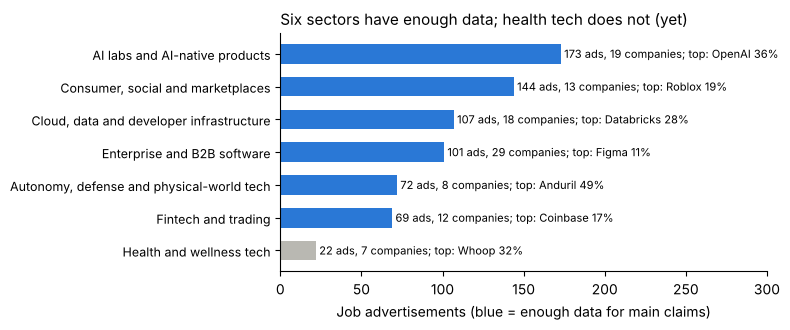

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
s = summ.sort_values("ads"); y = np.arange(len(s))
ax.barh(y, s.ads, color=[BLUE if m else GREY for m in s.main_sector], height=0.6)
ax.set_yticks(y); ax.set_yticklabels(s.sector, fontsize=9)
for i, r in enumerate(s.itertuples()):
    ax.text(r.ads + 2, i, f"{r.ads} ads, {r.companies} companies; top: {r.top_company} {r.top_company_share:.0%}", va="center", fontsize=8)
ax.set_xlim(0, 300); ax.set_xlabel("Job advertisements (blue = enough data for main claims)")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
ax.set_title("Six sectors have enough data; health tech does not (yet)", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

**Reading it.** Six sectors pass the threshold. Concentration matters: one company supplies 49% of the *Autonomy and defense* ads (Anduril) and 36% of the *AI labs* ads (OpenAI), which is exactly why the intervals below resample companies. **Health and wellness tech has only 22 ads from 7 companies, so it stays exploratory** (section 7).

Sector labels are my judgement from the company name. The borderline calls are below; the group should challenge them.

In [4]:
ct = company_table(jobs); ct[ct.note != ""].head(20)

,company,ads,sector,note
9,Scale AI,17,AI labs and AI-native products,AI data services (AI-native vs infrastructure)
16,Samsara,10,"Autonomy, defense and physical-world tech",IoT for operations (physical vs enterprise)
18,Mercor,9,AI labs and AI-native products,AI hiring/data-labelling platform (AI-native vs enterprise)
22,Harvey,8,AI labs and AI-native products,AI for law (AI-native vs enterprise)
26,Glean,7,AI labs and AI-native products,enterprise AI search (AI-native vs enterprise)
33,Whoop,7,Health and wellness tech,wearable (health vs consumer)
36,Gusto,6,Enterprise and B2B software,payroll (enterprise vs fintech)
40,Jane Street,5,Fintech and trading,trading firm (fintech)
45,Justworks,4,Enterprise and B2B software,payroll and HR (enterprise vs fintech)
50,Toast,4,Enterprise and B2B software,restaurant software and payments (enterprise vs fintech)


## 2. S1: does the sector matter at all?
Statistic: the mean pairwise distance between sector demand profiles. Null: shuffle the sector labels **among companies** 2,000 times. The second test first subtracts each ad's *career average*, so it asks whether sector matters **beyond** the career mix.

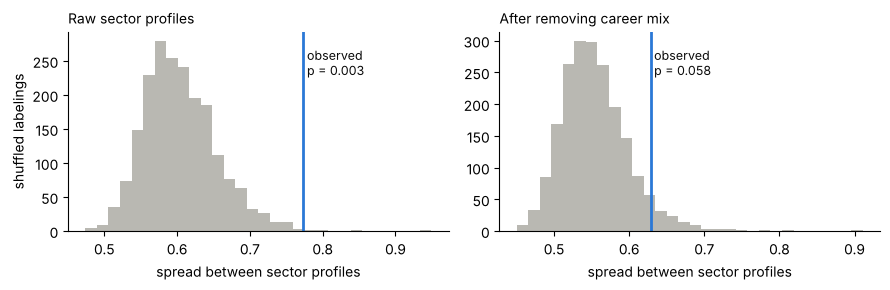

raw p = 0.0035   career-adjusted p = 0.0585


In [5]:
raw = M.permutation_test(MAIN, n_perm=2000)
adj = M.permutation_test(MAIN, n_perm=2000, adjust_career=True)
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=False)
for ax, r, ttl in zip(axes, [raw, adj], ["Raw sector profiles", "After removing career mix"]):
    ax.hist(r["null"], bins=30, color=GREY)
    ax.axvline(r["observed_spread"], color=BLUE, lw=2)
    ax.text(r["observed_spread"], ax.get_ylim()[1] * 0.92, f" observed\n p = {r['p_value']:.3f}", color=INK, fontsize=9, va="top")
    ax.set_title(ttl, loc="left", fontsize=10); ax.set_xlabel("spread between sector profiles")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axes[0].set_ylabel("shuffled labelings")
plt.tight_layout(); plt.show()
print(f"raw p = {raw['p_value']:.4f}   career-adjusted p = {adj['p_value']:.4f}")

**Reading it honestly.** Sector profiles differ far more than chance (raw p about 0.004). But a lot of that is **career mix**: Consumer ads are mostly Data Scientist and ML Engineer roles, Infrastructure ads mostly AI Engineer roles (table below). After removing career averages the evidence weakens to a borderline p of about 0.06. So the fair claim is: *sector differences exist and are largely, but perhaps not entirely, explained by which jobs each sector hires for.* We do not claim a clean sector effect.

In [6]:
pd.crosstab(jobs.company.map(SECTOR_OF), jobs.career_category, normalize="index").round(2).loc[MAIN]

career_category,AI Engineer,Data Analyst,Data Engineer,Data Scientist,ML Engineer
company,,,,,
AI labs and AI-native products,0.47,0.02,0.06,0.22,0.24
"Consumer, social and marketplaces",0.09,0.01,0.07,0.34,0.49
"Cloud, data and developer infrastructure",0.63,0.01,0.08,0.08,0.20
Enterprise and B2B software,0.54,0.05,0.07,0.15,0.19
"Autonomy, defense and physical-world tech",0.44,0.08,0.11,0.00,0.36
Fintech and trading,0.28,0.13,0.14,0.16,0.29


## 3. S2: a universal core, and what is distinctive per sector

In [7]:
D = M.demand_table().loc[MAIN]
core = D.min(axis=0).sort_values(ascending=False)
core = core[core >= 0.20]
print("Universal core: demand weight >= 0.20 in ALL six main sectors")
core.round(2).to_frame("weakest sector's demand")

Universal core: demand weight >= 0.20 in ALL six main sectors


,weakest sector's demand
Python,0.49
Artificial Intelligence,0.49
Machine Learning,0.41
Large Language Models,0.29


In [8]:
rows = []
for sct in MAIN:
    d = M.distinctive(sct, n_boot=1000, k=6)
    d.insert(0, "sector", sct); rows.append(d)
dist = pd.concat(rows)
shown = dist[["sector", "skill", "demand_in_sector", "demand_elsewhere", "difference", "ci_low", "ci_high", "robust"]].round(2)
shown

,sector,skill,demand_in_sector,demand_elsewhere,difference,ci_low,ci_high,robust
0,AI labs and AI-native products,TypeScript,0.13,0.09,0.04,-0.03,0.17,False
1,AI labs and AI-native products,Vector Databases,0.05,0.02,0.03,-0.02,0.12,False
2,AI labs and AI-native products,A/B Testing,0.08,0.06,0.02,-0.03,0.08,False
3,AI labs and AI-native products,Python,0.58,0.56,0.02,-0.09,0.13,False
4,AI labs and AI-native products,PostgreSQL,0.05,0.03,0.02,-0.03,0.12,False
5,AI labs and AI-native products,Reinforcement Learning,0.06,0.04,0.02,-0.02,0.07,False
0,"Consumer, social and marketplaces",Statistics,0.42,0.11,0.31,0.18,0.45,True
1,"Consumer, social and marketplaces",Machine Learning,0.75,0.45,0.30,0.16,0.40,True
2,"Consumer, social and marketplaces",Causal Inference,0.23,0.06,0.17,0.10,0.27,True
3,"Consumer, social and marketplaces",R,0.16,0.04,0.12,0.05,0.20,True


**How to read the table.** `difference` is demand in the sector minus demand elsewhere. `robust = True` means the company-clustered 95% interval excludes zero. Treat only robust rows as findings. Notably, the *AI labs* sector has **no** robust distinctive skill: it behaves like the market default. *Consumer* stands out for statistics, causal inference and R (but see the career-mix caveat), and *Autonomy* for computer vision, with a very wide interval because two companies dominate.

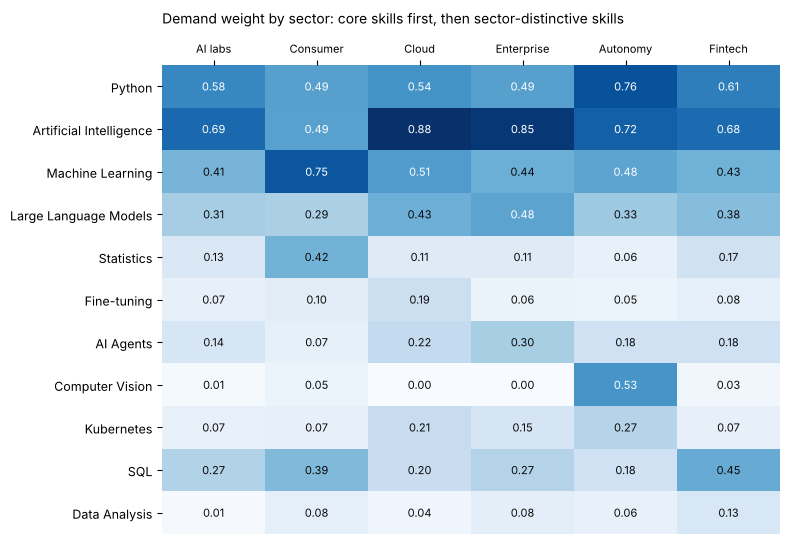

In [9]:
pick = list(dict.fromkeys(list(core.head(5).index) + list(dist[dist.robust].groupby("sector").head(2).skill)))
H = D[pick].T
fig, ax = plt.subplots(figsize=(8, 0.34 * len(H) + 1.8))
im = ax.imshow(H.values, cmap="Blues", vmin=0, vmax=max(0.8, H.values.max()), aspect="auto")
ax.set_xticks(range(len(MAIN))); ax.set_xticklabels([m.split(" and ")[0].split(",")[0] for m in MAIN], fontsize=8)
ax.set_yticks(range(len(H))); ax.set_yticklabels(H.index, fontsize=9); ax.xaxis.tick_top()
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.45 else INK)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Demand weight by sector: core skills first, then sector-distinctive skills", loc="left", fontsize=10, pad=30)
plt.tight_layout(); plt.show()

## 4. S3: curriculum coverage by sector
Using the **synthetic** demo units (not a real degree), coverage strength as in notebook 05, and company-clustered 95% intervals.

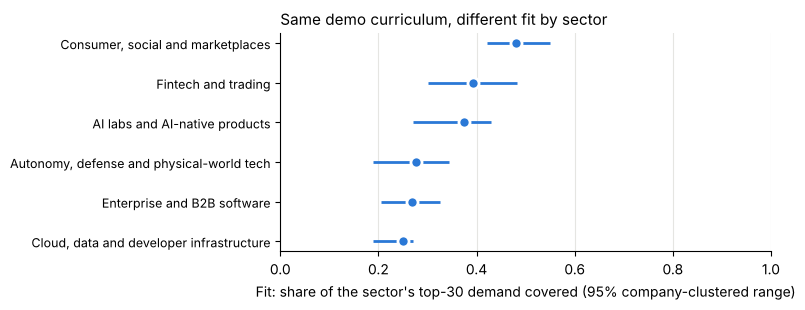

,sector,ads,fit,ci_low,ci_high
0,"Consumer, social and marketplaces",144,0.480,0.421,0.550
1,Fintech and trading,69,0.394,0.301,0.483
2,AI labs and AI-native products,173,0.375,0.271,0.430
3,"Autonomy, defense and physical-world tech",72,0.276,0.188,0.343
4,Enterprise and B2B software,101,0.269,0.205,0.325
5,"Cloud, data and developer infrastructure",107,0.250,0.188,0.271


In [10]:
from extraction import analyse_text
from alignment import curriculum_coverage
from demo_units import UNITS
cur = curriculum_coverage({u: analyse_text(t) for u, t in UNITS.items()})
cov = {s: d["weight"] for s, d in cur.items()}
fit = M.fit(cov, n_boot=500)
fit_main = fit[fit.sector.isin(MAIN)].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3.2))
f = fit_main.sort_values("fit"); y = np.arange(len(f))
ax.hlines(y, f.ci_low, f.ci_high, color=BLUE, lw=2); ax.plot(f.fit, y, "o", color=BLUE, ms=8, mec="white", mew=2)
ax.set_yticks(y); ax.set_yticklabels(f.sector, fontsize=9); ax.set_xlim(0, 1)
ax.set_xlabel("Fit: share of the sector's top-30 demand covered (95% company-clustered range)")
ax.set_title("Same demo curriculum, different fit by sector", loc="left", fontsize=11)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
ax.grid(axis="x", color="#e5e5e2", lw=.8); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
fit_main.round(3)

In [11]:
best, worst = fit_main.sector.iloc[0], fit_main.sector.iloc[-1]
print("Biggest gaps for the BEST-fitting sector:", best); display(M.gaps(cov, best, k=6, exclude=["Artificial Intelligence"]))
print("Biggest gaps for the WORST-fitting sector:", worst); M.gaps(cov, worst, k=6, exclude=["Artificial Intelligence"])

Biggest gaps for the BEST-fitting sector: Consumer, social and marketplaces


,skill,demand,current_coverage,marginal_gain
0,Large Language Models,0.293,0.0,0.293
1,Causal Inference,0.231,0.0,0.231
2,Data Pipelines,0.208,0.0,0.208
3,Apache Spark,0.207,0.0,0.207
4,TensorFlow,0.170,0.0,0.170
5,Generative AI,0.139,0.0,0.139


Biggest gaps for the WORST-fitting sector: Cloud, data and developer infrastructure


,skill,demand,current_coverage,marginal_gain
0,Large Language Models,0.435,0.0,0.435
1,Observability,0.283,0.0,0.283
2,APIs,0.255,0.0,0.255
3,Databricks,0.231,0.0,0.231
4,Snowflake,0.231,0.0,0.231
5,Distributed Systems,0.229,0.0,0.229


## 5. Exploratory only: health and wellness tech

In [12]:
hs = [i for i, c in enumerate(jobs.company) if SECTOR_OF[c] == "Health and wellness tech"]
hd = M.W[hs]
top = pd.Series(hd.mean(0), index=M.skills).sort_values(ascending=False).head(10)
print(len(hs), "ads from", jobs.company.iloc[hs].nunique(), "companies:", dict(jobs.company.iloc[hs].value_counts()))
top.round(2).to_frame("demand weight (exploratory, n=22)")

22 ads from 7 companies: {'Whoop': np.int64(7), 'Rula': np.int64(5), 'Headway': np.int64(3), 'Doximity': np.int64(3), 'Oura': np.int64(2), 'Maven Clinic': np.int64(1), 'Eight Sleep': np.int64(1)}


,"demand weight (exploratory, n=22)"
Artificial Intelligence,0.62
Python,0.62
Machine Learning,0.56
SQL,0.34
Large Language Models,0.30
AWS,0.24
Observability,0.20
dbt,0.20
TensorFlow,0.18
Data Quality,0.18


This is **not a finding**. Twenty-two ads from seven companies, mostly wearables, cannot describe a health sector. To promote it to a main sector the project needs about 40 more ads from at least a few more health-tech employers (the Greenhouse and Ashby collection scripts can do this) plus roughly 40 health-specific dictionary entries (for example EHR, FHIR, HL7, HIPAA, clinical NLP, medical imaging).

## 6. Limitations (put these in the report)
* **Sector labels are manual** and some are borderline (list above); results could shift if labels change. A group review is the cheapest fix.
* **Career mix confounds sector**: after adjustment the sector effect is only borderline (p about 0.06).
* **Concentration:** a few companies dominate some sectors; clustered intervals help but cannot create information that is not in the data.
* **The ad sample is mostly large tech companies and mostly from 2026**, so it is a benchmark of that part of the U.S. market, not the whole market.
* **The curriculum is synthetic** until real outlines are analysed; the fit chart shows the method, not a finding about UTS.